# Parameter-Driven Hypothesis Generation

Unlike the aggregate win-rate analysis in `hypothesis_mining.ipynb`, this notebook
identifies **which design parameter** drives each win and **for which outcome**.

**Key insight:** Most comparisons are the same base material vs itself (different
formulations). This means we can diff structured properties to find *which parameter
change* caused the difference.

**Outputs:**
- Parameter-outcome association table ("lower stiffness → better cell viability")
- Cross-paper design rules replicated across 2+ independent studies
- Tradeoff detection (parameter good for biology but bad for mechanics)
- Untested combination hypotheses
- Scored, ranked hypotheses with evidence citations

**Data source:** Local TTL files via rdflib, or Fuseki SPARQL endpoint (toggle `USE_LOCAL`)

## Setup & Connection

In [1]:
import json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from dotenv import load_dotenv
from collections import defaultdict
import os
import textwrap

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

# ── Toggle: True = load TTL files locally with rdflib, False = query Fuseki ──
USE_LOCAL = True

SEED_DATA_DIR = Path('..') / 'Data' / 'SeedData'

In [2]:
# Standard prefixes — prepended to every query
PREFIXES = """
PREFIX lova:   <https://lovamap.com/ontology#>
PREFIX dc:     <http://purl.org/dc/terms/>
PREFIX foaf:   <http://xmlns.com/foaf/0.1/>
PREFIX schema: <https://schema.org/>
PREFIX rdfs:   <http://www.w3.org/2000/01/rdf-schema#>
PREFIX rdf:    <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX xsd:    <http://www.w3.org/2001/XMLSchema#>
PREFIX text:   <http://jena.apache.org/text#>
PREFIX bibo:   <http://purl.org/ontology/bibo/>
PREFIX qudt:   <http://qudt.org/schema/qudt/>
"""

if USE_LOCAL:
    import rdflib

    graph = rdflib.Graph()
    ttl_files = sorted(SEED_DATA_DIR.glob('*.ttl'))
    print(f"Loading {len(ttl_files)} TTL files from {SEED_DATA_DIR.resolve()}...")
    for f in ttl_files:
        graph.parse(f, format='turtle')
    print(f"Loaded {len(graph):,} triples")

    graph.bind('dc', rdflib.Namespace('http://purl.org/dc/terms/'))

    def query(sparql: str, limit: int | None = None) -> pd.DataFrame:
        """Run a SPARQL SELECT against the local rdflib graph."""
        full_query = PREFIXES + sparql.strip()
        if limit is not None and 'LIMIT' not in sparql.upper():
            full_query += f"\nLIMIT {limit}"
        results = graph.query(full_query)
        cols = [str(v) for v in results.vars]
        rows = []
        for row in results:
            rows.append({col: str(val) if val is not None else '' for col, val in zip(cols, row)})
        return pd.DataFrame(rows, columns=cols)

else:
    load_dotenv(Path('..') / '..' / '.env')

    FUSEKI_BASE = os.environ['FUSEKI_URL'].rstrip('/')
    FUSEKI_DATASET = os.environ['FUSEKI_DATASET']
    FUSEKI_USER = 'admin'
    FUSEKI_PASS = os.environ['FUSEKI_ADMIN_PASSWORD']
    FUSEKI_QUERY_URL = f"{FUSEKI_BASE}/{FUSEKI_DATASET}/query"
    print(f"Fuseki endpoint: {FUSEKI_QUERY_URL}")

    def query(sparql: str, limit: int | None = None) -> pd.DataFrame:
        full_query = PREFIXES + sparql.strip()
        if limit is not None and 'LIMIT' not in sparql.upper():
            full_query += f"\nLIMIT {limit}"
        auth = (FUSEKI_USER, FUSEKI_PASS) if FUSEKI_USER else None
        resp = requests.post(
            FUSEKI_QUERY_URL,
            data=full_query.encode('utf-8'),
            headers={
                'Content-Type': 'application/sparql-query',
                'Accept': 'application/sparql-results+json',
            },
            auth=auth,
            timeout=60,
        )
        resp.raise_for_status()
        data = resp.json()
        cols = data['head']['vars']
        rows = []
        for binding in data['results']['bindings']:
            rows.append({v: binding.get(v, {}).get('value', '') for v in cols})
        return pd.DataFrame(rows, columns=cols)


def local_name(uri: str) -> str:
    if '#' in uri:
        return uri.split('#', 1)[1]
    return uri.rsplit('/', 1)[-1]


# Quick connectivity test
test = query("SELECT (COUNT(*) AS ?n) WHERE { ?s a bibo:AcademicArticle }")
print(f"Papers in knowledge base: {test.iloc[0]['n']}")

Loading 92 TTL files from /Users/dzen/Documents/LOVAMAP/Repos/LOVAMAP_GW/KnowledgeBaseBackend/Data/SeedData...
Loaded 72,266 triples
Papers in knowledge base: 92


## 1. Load All Comparisons with Full Material Properties

Single large query pulling every ComparisonResult with ALL material properties on
both sides, fabrication method properties, outcome details, and paper context.

In [3]:
# Load all comparisons with full material + fabrication properties on both sides
cmp_df = query("""
SELECT ?cmp ?cmpLabel ?direction ?significant ?pValue
       ?outA ?outALabel ?measTypeA ?measCatA
       ?outB ?outBLabel ?measTypeB ?measCatB
       ?matA ?matALabel
       ?particleMaterialA ?particleShapeA ?packingA ?surfaceModA
       ?stiffnessA ?stiffnessUnitA ?sizeMinA ?sizeMaxA
       ?annealingChemA ?mfgMethodA
       ?matB ?matBLabel
       ?particleMaterialB ?particleShapeB ?packingB ?surfaceModB
       ?stiffnessB ?stiffnessUnitB ?sizeMinB ?sizeMaxB
       ?annealingChemB ?mfgMethodB
       ?paperTitle ?doi
WHERE {
  ?cmp a lova:ComparisonResult ;
       rdfs:label ?cmpLabel ;
       lova:direction ?direction ;
       lova:outcomeA ?outA ;
       lova:outcomeB ?outB ;
       dc:source ?paper .

  ?paper dc:title ?paperTitle ;
         dc:identifier ?doi .

  OPTIONAL { ?cmp lova:isSignificant ?significant }
  OPTIONAL { ?cmp lova:pValue ?pValue }

  ?outA rdfs:label ?outALabel .
  OPTIONAL { ?outA lova:measurementType ?measTypeA }
  OPTIONAL { ?outA lova:measurementCategory ?measCatA }

  ?outB rdfs:label ?outBLabel .
  OPTIONAL { ?outB lova:measurementType ?measTypeB }
  OPTIONAL { ?outB lova:measurementCategory ?measCatB }

  # Material A properties
  OPTIONAL {
    ?cmp lova:materialA ?matA .
    ?matA rdfs:label ?matALabel .
    OPTIONAL { ?matA lova:particleMaterial ?particleMaterialA }
    OPTIONAL { ?matA lova:particleShape ?particleShapeA }
    OPTIONAL { ?matA lova:packingConfiguration ?packingA }
    OPTIONAL { ?matA lova:surfaceModification ?surfaceModA }
    OPTIONAL { ?matA lova:stiffnessValue ?stiffnessA }
    OPTIONAL { ?matA lova:stiffnessUnit ?stiffnessUnitA }
    OPTIONAL { ?matA lova:particleSizeMin ?sizeMinA }
    OPTIONAL { ?matA lova:particleSizeMax ?sizeMaxA }
    OPTIONAL {
      ?matA lova:hasFabricationMethod ?fabA .
      OPTIONAL { ?fabA lova:annealingChemistry ?annealingChemA }
      OPTIONAL { ?fabA lova:manufacturingMethod ?mfgMethodA }
    }
  }

  # Material B properties
  OPTIONAL {
    ?cmp lova:materialB ?matB .
    ?matB rdfs:label ?matBLabel .
    OPTIONAL { ?matB lova:particleMaterial ?particleMaterialB }
    OPTIONAL { ?matB lova:particleShape ?particleShapeB }
    OPTIONAL { ?matB lova:packingConfiguration ?packingB }
    OPTIONAL { ?matB lova:surfaceModification ?surfaceModB }
    OPTIONAL { ?matB lova:stiffnessValue ?stiffnessB }
    OPTIONAL { ?matB lova:stiffnessUnit ?stiffnessUnitB }
    OPTIONAL { ?matB lova:particleSizeMin ?sizeMinB }
    OPTIONAL { ?matB lova:particleSizeMax ?sizeMaxB }
    OPTIONAL {
      ?matB lova:hasFabricationMethod ?fabB .
      OPTIONAL { ?fabB lova:annealingChemistry ?annealingChemB }
      OPTIONAL { ?fabB lova:manufacturingMethod ?mfgMethodB }
    }
  }
}
""")

print(f"Total comparison rows: {len(cmp_df)}")
print(f"Unique comparisons: {cmp_df['cmp'].nunique()}")
print(f"\nDirection distribution:")
print(cmp_df.drop_duplicates('cmp')['direction'].value_counts())
print(f"\nSignificance: {cmp_df.drop_duplicates('cmp')['significant'].value_counts().to_dict()}")

Total comparison rows: 955
Unique comparisons: 853

Direction distribution:
direction
higher           531
lower            231
no difference     91
Name: count, dtype: int64

Significance: {'true': 536, '': 246, 'false': 71}


In [62]:
# ── Deduplicate: the SPARQL query can produce multiple rows per comparison
# when a material has multiple fabrication methods. Keep one row per comparison,
# preferring rows that have the most filled-in property columns.
prop_cols = [
    'particleMaterialA', 'particleShapeA', 'packingA', 'surfaceModA',
    'stiffnessA', 'sizeMinA', 'sizeMaxA', 'annealingChemA', 'mfgMethodA',
    'particleMaterialB', 'particleShapeB', 'packingB', 'surfaceModB',
    'stiffnessB', 'sizeMinB', 'sizeMaxB', 'annealingChemB', 'mfgMethodB',
]
cmp_df['_prop_fill'] = cmp_df[prop_cols].apply(lambda r: sum(v != '' for v in r), axis=1)
cmp_df = cmp_df.sort_values('_prop_fill', ascending=False).drop_duplicates('cmp').drop(columns='_prop_fill')
cmp_df = cmp_df.reset_index(drop=True)

# ── Tag comparison type: same_material, cross_material, or material_unknown ──
def classify_comparison(row):
    if row['matA'] == '' or row['matB'] == '':
        if row['matA'] == '' and row['matB'] == '':
            return 'material_unknown'
        return 'material_unknown'  # only one side linked
    mat_a = row.get('particleMaterialA', '')
    mat_b = row.get('particleMaterialB', '')
    if row['matA'] == row['matB']:
        return 'same_material'  # same URI
    if mat_a != '' and mat_b != '' and mat_a == mat_b:
        return 'same_material'  # same base material, different formulations
    if mat_a != '' and mat_b != '' and mat_a != mat_b:
        return 'cross_material'
    # Labels differ but no particleMaterial to compare
    if row['matALabel'] != row['matBLabel']:
        return 'cross_material'  # conservative: different labels = different materials
    return 'same_material'

cmp_df['cmp_type'] = cmp_df.apply(classify_comparison, axis=1)

print("Comparison type distribution:")
print(cmp_df['cmp_type'].value_counts())
print(f"\nTotal unique comparisons after dedup: {len(cmp_df)}")

Comparison type distribution:
cmp_type
same_material       567
cross_material      199
material_unknown     87
Name: count, dtype: int64

Total unique comparisons after dedup: 853


## 2. Parameter Diff Detection Engine

For each comparison, identify **which structured properties differ** between
materialA and materialB. This is the core innovation: instead of asking "which
material wins?", we ask "which *parameter change* is associated with winning?"

In [63]:
# ── Define comparable property pairs ──
# Each tuple: (display_name, colA, colB, type)
# type: 'categorical' for string comparisons, 'quantitative' for numeric
PROPERTY_PAIRS = [
    ('particleShape',      'particleShapeA',    'particleShapeB',    'categorical'),
    ('packing',            'packingA',          'packingB',          'categorical'),
    ('surfaceModification','surfaceModA',       'surfaceModB',       'categorical'),
    ('stiffness',          'stiffnessA',        'stiffnessB',        'quantitative'),
    ('sizeMin',            'sizeMinA',          'sizeMinB',          'quantitative'),
    ('sizeMax',            'sizeMaxA',          'sizeMaxB',          'quantitative'),
    ('annealingChemistry', 'annealingChemA',    'annealingChemB',    'categorical'),
    ('manufacturingMethod','mfgMethodA',        'mfgMethodB',        'categorical'),
    ('particleMaterial',   'particleMaterialA', 'particleMaterialB', 'categorical'),
]


def find_diffs(row):
    """For a comparison row, return list of diffs between material A and B.
    
    Each diff is a dict with:
      param, valueA, valueB, param_type,
      higher_value (for quantitative: which numeric value is larger),
      winner_has_higher (for quantitative: does the winning side have the higher value)
    """
    diffs = []
    for param_name, col_a, col_b, ptype in PROPERTY_PAIRS:
        val_a = str(row.get(col_a, '')).strip()
        val_b = str(row.get(col_b, '')).strip()
        # Skip if both are empty
        if val_a == '' or val_b == '':
            continue
        # Skip if they are the same
        if val_a == val_b:
            continue
        
        diff = {
            'param': param_name,
            'valueA': val_a,
            'valueB': val_b,
            'param_type': ptype,
        }
        
        # For quantitative params, determine direction
        if ptype == 'quantitative':
            try:
                num_a = float(val_a) if val_a else None
                num_b = float(val_b) if val_b else None
                if num_a is not None and num_b is not None:
                    diff['winner_has_higher'] = num_a > num_b  # A is the "winner" side
                    diff['numeric_diff'] = num_a - num_b
                else:
                    diff['winner_has_higher'] = None
                    diff['numeric_diff'] = None
            except (ValueError, TypeError):
                diff['winner_has_higher'] = None
                diff['numeric_diff'] = None
        
        diffs.append(diff)
    return diffs


print(f"Defined {len(PROPERTY_PAIRS)} property pairs for diff detection")

Defined 9 property pairs for diff detection


In [64]:
# ── Explode into long-form DataFrame: one row per (comparison × differing parameter) ──
diff_rows = []
for _, row in cmp_df.iterrows():
    diffs = find_diffs(row)
    n_diffs = len(diffs)
    
    if n_diffs == 0:
        # No structured properties differ — diff is only in rdfs:label text
        diff_rows.append({
            'cmp': row['cmp'],
            'cmpLabel': row['cmpLabel'],
            'direction': row['direction'],
            'significant': row['significant'],
            'measCatA': row.get('measCatA', ''),
            'measTypeA': row.get('measTypeA', ''),
            'matALabel': row.get('matALabel', ''),
            'matBLabel': row.get('matBLabel', ''),
            'particleMaterialA': row.get('particleMaterialA', ''),
            'doi': row['doi'],
            'paperTitle': row['paperTitle'],
            'cmp_type': row['cmp_type'],
            'param': 'UNSTRUCTURED',
            'valueA': row.get('matALabel', ''),
            'valueB': row.get('matBLabel', ''),
            'param_type': 'unstructured',
            'winner_has_higher': None,
            'numeric_diff': None,
            'n_diffs': 0,
        })
    else:
        for d in diffs:
            diff_rows.append({
                'cmp': row['cmp'],
                'cmpLabel': row['cmpLabel'],
                'direction': row['direction'],
                'significant': row['significant'],
                'measCatA': row.get('measCatA', ''),
                'measTypeA': row.get('measTypeA', ''),
                'matALabel': row.get('matALabel', ''),
                'matBLabel': row.get('matBLabel', ''),
                'particleMaterialA': row.get('particleMaterialA', ''),
                'doi': row['doi'],
                'paperTitle': row['paperTitle'],
                'cmp_type': row['cmp_type'],
                'param': d['param'],
                'valueA': d['valueA'],
                'valueB': d['valueB'],
                'param_type': d['param_type'],
                'winner_has_higher': d.get('winner_has_higher'),
                'numeric_diff': d.get('numeric_diff'),
                'n_diffs': n_diffs,
            })

diff_df = pd.DataFrame(diff_rows)
print(f"Total diff rows: {len(diff_df)}")
print(f"Comparisons with structured diffs: {diff_df[diff_df['param'] != 'UNSTRUCTURED']['cmp'].nunique()}")
print(f"Comparisons with only UNSTRUCTURED diffs: {diff_df[diff_df['param'] == 'UNSTRUCTURED']['cmp'].nunique()}")
print(f"\nDiffs per parameter:")
print(diff_df['param'].value_counts())

Total diff rows: 1008
Comparisons with structured diffs: 372
Comparisons with only UNSTRUCTURED diffs: 481

Diffs per parameter:
param
UNSTRUCTURED           481
particleMaterial       130
manufacturingMethod    113
surfaceModification     96
packing                 50
stiffness               42
sizeMin                 34
sizeMax                 33
annealingChemistry      18
particleShape           11
Name: count, dtype: int64


In [65]:
# ── Confounding analysis: how many diffs per comparison? ──
# Single-diff comparisons provide the cleanest signal
structured = diff_df[diff_df['param'] != 'UNSTRUCTURED']
diffs_per_cmp = structured.groupby('cmp')['param'].count().value_counts().sort_index()

print("Number of differing parameters per comparison:")
for n, count in diffs_per_cmp.items():
    tag = ' ← cleanest signal' if n == 1 else (' ← confounded' if n >= 3 else '')
    print(f"  {n} diff(s): {count} comparisons{tag}")

# Flag clean (single-diff) comparisons
diff_df['is_clean'] = (diff_df['n_diffs'] == 1) & (diff_df['param'] != 'UNSTRUCTURED')
print(f"\nClean single-diff comparisons: {diff_df[diff_df['is_clean']]['cmp'].nunique()}")

Number of differing parameters per comparison:
  1 diff(s): 243 comparisons ← cleanest signal
  2 diff(s): 109 comparisons
  3 diff(s): 18 comparisons ← confounded
  6 diff(s): 2 comparisons ← confounded

Clean single-diff comparisons: 243


## 3. Parameter–Outcome Table

For each differing parameter, show which value wins for which outcome type.
This is the core output: **"Parameter X value Y beats value Z for outcome W."**

In [66]:
# ── Build the parameter-outcome association table ──
# Focus on significant, directional comparisons
sig_diffs = diff_df[
    (diff_df['significant'] == 'true') &
    (diff_df['direction'].isin(['higher', 'lower'])) &
    (diff_df['param'] != 'UNSTRUCTURED')
].copy()

print(f"Significant structured diff rows: {len(sig_diffs)}")

# For each (parameter, winner_value, loser_value, outcome_category), count wins and papers
param_outcome_rows = []
for (param, valA, valB, measCat), group in sig_diffs.groupby(
    ['param', 'valueA', 'valueB', 'measCatA']
):
    if measCat == '':
        continue
    papers = group['doi'].nunique()
    wins = len(group)
    base_materials = group['particleMaterialA'].unique()
    base_mat_str = ', '.join(m for m in base_materials if m != '')[:60]
    
    row = {
        'parameter': param,
        'winner_value': valA,
        'loser_value': valB,
        'outcome_category': measCat,
        'wins': wins,
        'papers': papers,
        'base_material': base_mat_str,
    }
    
    # For quantitative params, track direction
    if param in ('stiffness', 'sizeMin', 'sizeMax'):
        higher_wins = group['winner_has_higher'].dropna()
        if len(higher_wins) > 0:
            frac_higher = higher_wins.mean()
            row['direction_note'] = f"higher wins {frac_higher:.0%}" if frac_higher > 0.5 else f"lower wins {1-frac_higher:.0%}"
        else:
            row['direction_note'] = ''
    else:
        row['direction_note'] = ''
    
    param_outcome_rows.append(row)

param_outcome_df = pd.DataFrame(param_outcome_rows)
param_outcome_df = param_outcome_df.sort_values(['wins', 'papers'], ascending=False)
print(f"\nParameter-outcome associations: {len(param_outcome_df)}")
print(f"\nTop 20 by win count:")
display(param_outcome_df.head(20))

Significant structured diff rows: 295

Parameter-outcome associations: 162

Top 20 by win count:


,parameter,winner_value,loser_value,outcome_category,wins,papers,base_material,direction_note
125,surfaceModification,Citrullinated (PAD2+PAD4 treated),Unmodified (native),Biological,10,1,Fibronectin,
31,packing,2D,Jammed,Biological,9,1,,
37,packing,Non-porous,Hexagonal,Biological,8,1,HA,
0,annealingChemistry,Enzymatic (FXIIIa),Enzymatic (FXIIIa and thrombin added to mimic microgel condition),Biological,7,1,HA-AC,
10,manufacturingMethod,Microfluidic flow-focusing water-in-oil emulsion,Bulk in situ gelation (no microfluidic emulsification),Biological,7,1,HA-AC,
8,manufacturingMethod,Flash-freezing/lyophilization; incorporation of SDF-1 nH prior to injection,Flash-freezing in liquid nitrogen and lyophilization in Tris HCl/NaCl/CaCl2 ...,Biological,6,1,HA-NB,
12,manufacturingMethod,Microfluidic water-in-oil emulsion,Bulk mixing / bulk hydrogel casting,Biological,6,1,PEG-VS,
135,surfaceModification,"IKVAV, YIGSR, RGD-modified; SDF-1 bound heparin nanoparticles","IKVAV, YIGSR, RGD-modified",Biological,6,1,HA-NB,
144,surfaceModification,"RGD 10 μM, homogeneous (condition 1, least clustered)","RGD 10 μM, 1.4% of total HA-AC reacted with RGD, 1.8 mmol RGD/mmol HA-RGD",Biological,6,1,HA-AC,
25,manufacturingMethod,"Sandwiched between Sigmacoted slides with 1 mm plastic spacers, no templating","PMMA microsphere (53-63 μm) templating, centrifugation perfusion at 1500 rpm...",Biological,5,1,HA,


In [67]:
# ── Focus on clean (single-diff) comparisons for unconfounded signal ──
clean_sig_diffs = sig_diffs[sig_diffs['is_clean']].copy()
print(f"Clean single-diff significant rows: {len(clean_sig_diffs)}")

clean_param_outcome = []
for (param, valA, valB, measCat), group in clean_sig_diffs.groupby(
    ['param', 'valueA', 'valueB', 'measCatA']
):
    if measCat == '':
        continue
    papers = group['doi'].nunique()
    wins = len(group)
    base_mat_str = ', '.join(m for m in group['particleMaterialA'].unique() if m != '')[:60]
    
    row = {
        'parameter': param,
        'winner_value': valA,
        'loser_value': valB,
        'outcome_category': measCat,
        'wins': wins,
        'papers': papers,
        'base_material': base_mat_str,
    }
    if param in ('stiffness', 'sizeMin', 'sizeMax'):
        higher_wins = group['winner_has_higher'].dropna()
        if len(higher_wins) > 0:
            frac_higher = higher_wins.mean()
            row['direction_note'] = f"higher wins {frac_higher:.0%}" if frac_higher > 0.5 else f"lower wins {1-frac_higher:.0%}"
        else:
            row['direction_note'] = ''
    else:
        row['direction_note'] = ''
    clean_param_outcome.append(row)

clean_param_outcome_df = pd.DataFrame(clean_param_outcome)
if not clean_param_outcome_df.empty:
    clean_param_outcome_df = clean_param_outcome_df.sort_values(['wins', 'papers'], ascending=False)
    print(f"\nClean parameter-outcome associations: {len(clean_param_outcome_df)}")
    print("\nTop associations from single-diff (unconfounded) comparisons:")
    display(clean_param_outcome_df.head(20))
else:
    print("No clean single-diff associations found")

Clean single-diff significant rows: 150

Clean parameter-outcome associations: 88

Top associations from single-diff (unconfounded) comparisons:


,parameter,winner_value,loser_value,outcome_category,wins,papers,base_material,direction_note
55,surfaceModification,Citrullinated (PAD2+PAD4 treated),Unmodified (native),Biological,10,1,Fibronectin,
9,packing,2D,Jammed,Biological,9,1,,
2,manufacturingMethod,Microfluidic water-in-oil emulsion,Bulk mixing / bulk hydrogel casting,Biological,6,1,PEG-VS,
72,surfaceModification,"RGD 10 μM, homogeneous (condition 1, least clustered)","RGD 10 μM, 1.4% of total HA-AC reacted with RGD, 1.8 mmol RGD/mmol HA-RGD",Biological,6,1,HA-AC,
4,manufacturingMethod,Oxygen plasma treatment followed by silanization and wet-dry dip coating (10...,Oxygen plasma treatment followed by silanization and wet-dry dip coating (10...,Biological,4,1,Stainless Steel,
45,particleMaterial,sPEG-PEI (PEGylated low-molecular-weight PEI),Linear PEI (25 kDa),Biological,4,1,sPEG-PEI (PEGylated low-molecular-weight PEI),
49,stiffness,2500.0,500.0,Biological,4,1,PEG-VS,higher wins 100%
62,surfaceModification,Fn9*10 (10μM),Fn9(4G)10 (10μM),Biological,4,1,HA-AC,
73,surfaceModification,"RGD 10 μM, homogeneous (condition 1, least clustered)","RGD 10 μM, 21% of total HA-AC reacted with RGD",Biological,4,1,HA-AC,
79,surfaceModification,"RGD 100μM, YIGSR 48μM, IKVAV 300μM (DOE-optimized concentrations)","RGD 300μM, RDG 150μM",Biological,4,1,HA-AC,


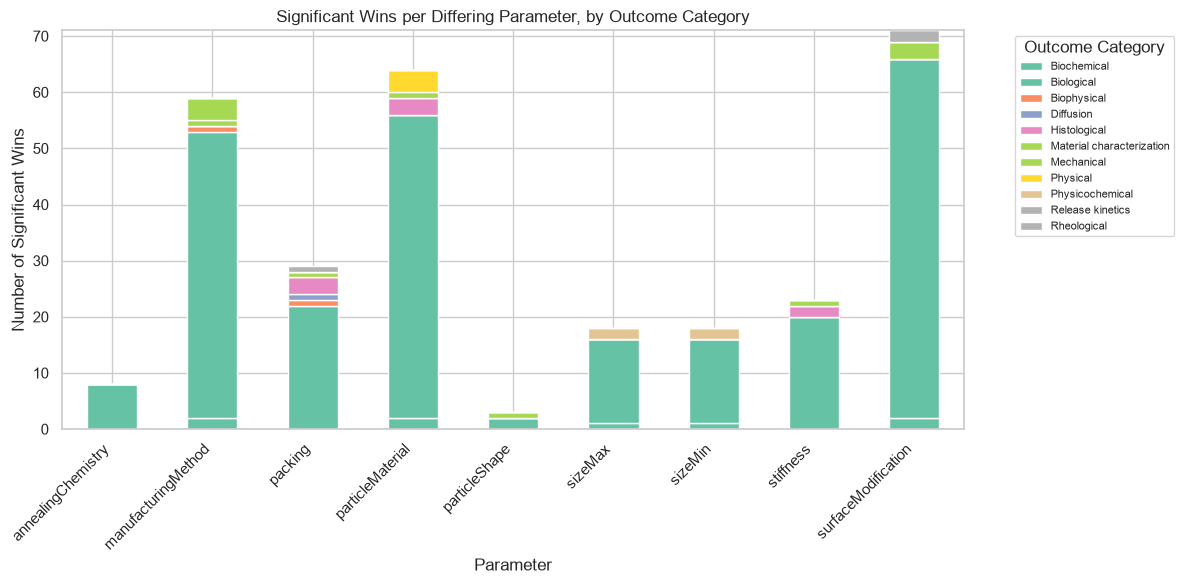

In [68]:
# ── Visualization: wins per parameter, colored by outcome category ──
if not param_outcome_df.empty:
    viz = param_outcome_df.groupby(['parameter', 'outcome_category'])['wins'].sum().reset_index()
    pivot_viz = viz.pivot_table(index='parameter', columns='outcome_category',
                                values='wins', fill_value=0)
    
    fig, ax = plt.subplots(figsize=(12, 6))
    pivot_viz.plot.bar(stacked=True, ax=ax, colormap='Set2')
    ax.set_title('Significant Wins per Differing Parameter, by Outcome Category')
    ax.set_xlabel('Parameter')
    ax.set_ylabel('Number of Significant Wins')
    ax.legend(title='Outcome Category', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print("No data for visualization")

## 4. Cross-Paper Design Rules

The most reliable findings: parameter-outcome associations that replicate
across **2+ independent papers**. These are actionable design rules.

In [69]:
# ── Aggregate design rules across papers ──
# Group by (parameter, outcome_category) and aggregate directionally
design_rule_rows = []

for (param, measCat), group in sig_diffs.groupby(['param', 'measCatA']):
    if measCat == '':
        continue
    
    papers = group['doi'].nunique()
    total_wins = len(group)
    base_materials = sorted(set(m for m in group['particleMaterialA'].unique() if m != ''))
    
    rule = {
        'parameter': param,
        'outcome_category': measCat,
        'total_wins': total_wins,
        'papers': papers,
        'base_materials': ', '.join(base_materials)[:80],
        'n_base_materials': len(base_materials),
    }
    
    # For quantitative params, determine if "higher" or "lower" consistently wins
    if param in ('stiffness', 'sizeMin', 'sizeMax'):
        higher_wins = group['winner_has_higher'].dropna()
        if len(higher_wins) >= 2:
            frac_higher = higher_wins.mean()
            rule['quant_direction'] = 'higher wins' if frac_higher > 0.6 else (
                'lower wins' if frac_higher < 0.4 else 'mixed'
            )
            rule['consistency'] = max(frac_higher, 1 - frac_higher)
        else:
            rule['quant_direction'] = ''
            rule['consistency'] = 0.0
    else:
        # For categorical: find the most common winning value
        top_val = group['valueA'].value_counts()
        if len(top_val) > 0:
            rule['top_winner'] = top_val.index[0]
            rule['consistency'] = top_val.iloc[0] / total_wins
        else:
            rule['top_winner'] = ''
            rule['consistency'] = 0.0
        rule['quant_direction'] = ''
    
    design_rule_rows.append(rule)

design_rules_df = pd.DataFrame(design_rule_rows)
design_rules_df = design_rules_df.sort_values(['papers', 'total_wins'], ascending=False)

print("=== Cross-Paper Design Rules (2+ papers) ===")
cross_paper_rules = design_rules_df[design_rules_df['papers'] >= 2].copy()
print(f"Found {len(cross_paper_rules)} rules replicated across 2+ papers\n")
display(cross_paper_rules.head(25))

=== Cross-Paper Design Rules (2+ papers) ===
Found 14 rules replicated across 2+ papers



,parameter,outcome_category,total_wins,papers,base_materials,n_base_materials,top_winner,consistency,quant_direction
13,particleMaterial,Biological,54,18,"4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker, 4-arm PEG-vinyl sulfon...",24,HA-AC,0.129630,
2,manufacturingMethod,Biological,51,15,"HA, HA-AC, HA-NB, Heparin, PEG-VS, Stainless Steel",6,"Sandwiched between Sigmacoted slides with 1 mm plastic spacers, no templating",0.156863,
29,surfaceModification,Biological,64,14,"Fibrin, Fibronectin, HA, HA-AC, HA-NB, Plasmid DNA / PEI / RGD-gold-nanoclus...",7,"RGD 10 μM, homogeneous (condition 1, least clustered)",0.156250,
20,sizeMax,Biological,15,7,"8-arm PEG Vinylsulfone, HA, HA-AC, HA-NB, PEG-VS, PEI/DNA polyplex",6,NaN,0.733333,lower wins
23,sizeMin,Biological,15,7,"8-arm PEG Vinylsulfone, HA, HA-AC, HA-NB, PEG-VS, PEI/DNA polyplex",6,NaN,0.733333,lower wins
25,stiffness,Biological,20,6,"4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker, HA, HA-AC, PEG-VS",4,NaN,0.600000,mixed
6,packing,Biological,22,5,"HA, HA-NB, PEG-VS",3,2D,0.409091,
5,manufacturingMethod,Mechanical,4,4,"HA-AC, PEG-VS, PMMA",3,Heat sintering of packed PMMA microspheres,0.250000,
0,annealingChemistry,Biological,8,2,"HA-AC, HA-NB",2,Enzymatic (FXIIIa),0.875000,
16,particleMaterial,Physical,4,2,"Hyaluronic acid + rat tail collagen, PEG45-PPS5-K9 (PEG-poly(propylene sulfi...",3,PEG45-PPS5-TAT (PEG-poly(propylene sulfide)-TAT peptide),0.500000,


In [70]:
# ── Generate natural-language design rules ──
nl_rules = []

for _, rule in cross_paper_rules.iterrows():
    param = rule['parameter']
    outcome = rule['outcome_category']
    papers = rule['papers']
    wins = rule['total_wins']
    mats = rule['base_materials']
    
    if rule.get('quant_direction', ''):
        direction = rule['quant_direction']
        text = (f"For {param}: {direction} is associated with improved {outcome} outcomes "
                f"({wins} wins across {papers} papers). "
                f"Consistency: {rule['consistency']:.0%}. Base materials: {mats}")
    elif rule.get('top_winner', ''):
        winner = rule['top_winner']
        text = (f"For {param}: '{winner}' is the top-performing value for {outcome} outcomes "
                f"({wins} wins across {papers} papers). "
                f"Consistency: {rule['consistency']:.0%}. Base materials: {mats}")
    else:
        text = (f"{param} differences are associated with {outcome} outcome variation "
                f"({wins} wins across {papers} papers). Base materials: {mats}")
    
    nl_rules.append({'rule': text, 'papers': papers, 'wins': wins, 'parameter': param, 'outcome': outcome})

nl_rules_df = pd.DataFrame(nl_rules)

print("=== Natural-Language Design Rules ===\n")
for i, row in nl_rules_df.head(15).iterrows():
    print(f"{i+1}. {row['rule']}\n")

=== Natural-Language Design Rules ===

1. For particleMaterial: 'HA-AC' is the top-performing value for Biological outcomes (54 wins across 18 papers). Consistency: 13%. Base materials: 4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker, 4-arm PEG-vinyl sulfone, L

2. For manufacturingMethod: 'Sandwiched between Sigmacoted slides with 1 mm plastic spacers, no templating' is the top-performing value for Biological outcomes (51 wins across 15 papers). Consistency: 16%. Base materials: HA, HA-AC, HA-NB, Heparin, PEG-VS, Stainless Steel

3. For surfaceModification: 'RGD 10 μM, homogeneous (condition 1, least clustered)' is the top-performing value for Biological outcomes (64 wins across 14 papers). Consistency: 16%. Base materials: Fibrin, Fibronectin, HA, HA-AC, HA-NB, Plasmid DNA / PEI / RGD-gold-nanocluster 

4. For sizeMax: lower wins is associated with improved Biological outcomes (15 wins across 7 papers). Consistency: 73%. Base materials: 8-arm PEG Vinylsulfone, HA, HA-AC, HA-NB, 

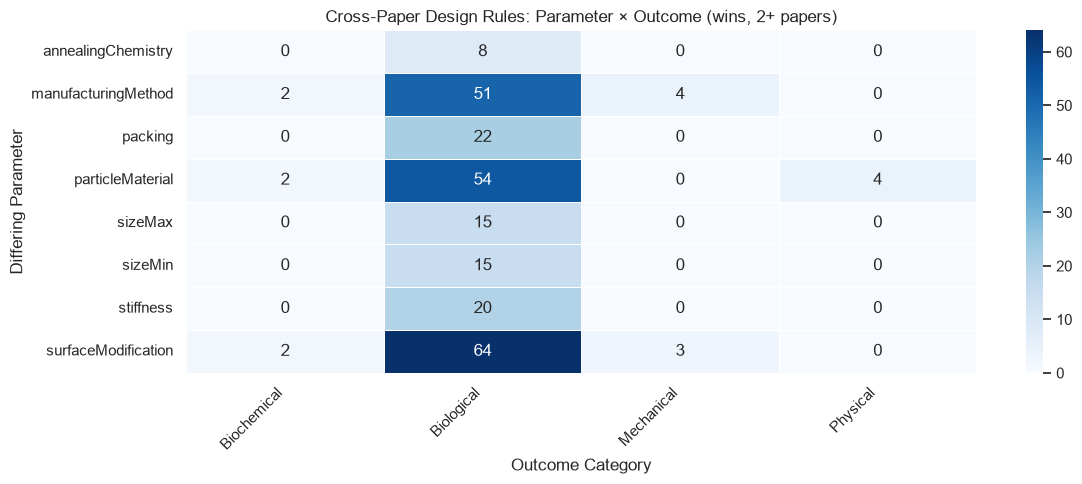

In [71]:
# ── Design rules heatmap: parameter × outcome ──
if not cross_paper_rules.empty:
    rule_pivot = cross_paper_rules.pivot_table(
        index='parameter', columns='outcome_category',
        values='total_wins', fill_value=0
    )
    
    fig, ax = plt.subplots(figsize=(12, max(5, len(rule_pivot) * 0.6)))
    sns.heatmap(rule_pivot, annot=True, fmt='g', cmap='Blues', ax=ax,
                linewidths=0.5, linecolor='white')
    ax.set_title('Cross-Paper Design Rules: Parameter × Outcome (wins, 2+ papers)')
    ax.set_xlabel('Outcome Category')
    ax.set_ylabel('Differing Parameter')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

## 5. Outcome-Specific Rankings

For each outcome category, rank which parameter values perform best.
Answers: "If I want to optimize for cell viability, what should I choose?"

In [72]:
# ── For each outcome category, rank parameter values by win frequency ──
outcome_cats = sig_diffs['measCatA'].value_counts()
print("Outcome categories available:")
print(outcome_cats[outcome_cats >= 5])

outcome_rankings = {}

for cat in outcome_cats[outcome_cats >= 5].index:
    if cat == '':
        continue
    cat_diffs = sig_diffs[sig_diffs['measCatA'] == cat]
    
    rankings = []
    for param in cat_diffs['param'].unique():
        param_data = cat_diffs[cat_diffs['param'] == param]
        
        if param in ('stiffness', 'sizeMin', 'sizeMax'):
            # Quantitative: report direction
            higher_wins = param_data['winner_has_higher'].dropna()
            if len(higher_wins) > 0:
                frac_higher = higher_wins.mean()
                direction = 'Higher' if frac_higher > 0.5 else 'Lower'
                rankings.append({
                    'parameter': param,
                    'recommendation': f"{direction} {param}",
                    'wins': len(param_data),
                    'papers': param_data['doi'].nunique(),
                    'confidence': max(frac_higher, 1 - frac_higher),
                })
        else:
            # Categorical: report top winning value
            top_vals = param_data['valueA'].value_counts().head(3)
            for val, count in top_vals.items():
                val_data = param_data[param_data['valueA'] == val]
                rankings.append({
                    'parameter': param,
                    'recommendation': val[:60],
                    'wins': count,
                    'papers': val_data['doi'].nunique(),
                    'confidence': count / len(param_data),
                })
    
    if rankings:
        rank_df = pd.DataFrame(rankings).sort_values('wins', ascending=False)
        outcome_rankings[cat] = rank_df

Outcome categories available:
measCatA
Biological      251
Mechanical       10
Biochemical       8
Histological      8
Name: count, dtype: int64


In [73]:
# ── Display outcome-specific rankings ──
for cat, rank_df in sorted(outcome_rankings.items(), key=lambda x: -len(x[1])):
    print(f"\n{'='*60}")
    print(f"Outcome: {cat}")
    print(f"{'='*60}")
    top = rank_df.head(10).copy()
    top['confidence'] = top['confidence'].map('{:.0%}'.format)
    display(top)


Outcome: Biological


,parameter,recommendation,wins,papers,confidence
16,stiffness,Higher stiffness,20,6,60%
6,sizeMin,Lower sizeMin,15,7,73%
7,sizeMax,Lower sizeMax,15,7,73%
0,surfaceModification,"RGD 10 μM, homogeneous (condition 1, least clustered)",10,1,16%
1,surfaceModification,Citrullinated (PAD2+PAD4 treated),10,1,16%
13,packing,2D,9,1,41%
10,manufacturingMethod,Sandwiched between Sigmacoted slides with 1 mm plastic space,8,1,16%
14,packing,Non-porous,8,1,36%
3,particleMaterial,HA-AC,7,2,13%
8,annealingChemistry,Enzymatic (FXIIIa),7,1,88%



Outcome: Mechanical


,parameter,recommendation,wins,papers,confidence
0,stiffness,Higher stiffness,1,1,100%
1,manufacturingMethod,Heat sintering of packed PMMA microspheres,1,1,25%
2,manufacturingMethod,"Sacrificial PMMA microsphere templating (90-106 μm beads), c",1,1,25%
3,manufacturingMethod,"Mixing of plasmid DNA with linear PEI in DI water, vortex an",1,1,25%
4,particleMaterial,"4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker",1,1,100%
5,surfaceModification,RGD + high IKVAV + YIGSR,1,1,33%
6,surfaceModification,Unmodified (native),1,1,33%
7,surfaceModification,Citrullinated (PAD2+PAD4 treated),1,1,33%
8,packing,Porous (PMMA-templated),1,1,100%



Outcome: Biochemical


,parameter,recommendation,wins,papers,confidence
0,sizeMin,Lower sizeMin,1,1,100%
1,sizeMax,Lower sizeMax,1,1,100%
2,surfaceModification,"Biotin-functionalized, neutravidin-coated",1,1,50%
3,surfaceModification,VEGF bound via heparin-binding domain then UV covalently loc,1,1,50%
4,manufacturingMethod,"Aqueous solution reaction, dialysis purification (MWCO 14000",1,1,50%
5,manufacturingMethod,VEGF (200 ng/ml in PBS) incubated 24 h at 4°C on heparin-ABH,1,1,50%
6,particleMaterial,Biotinylated hyaluronic acid,1,1,50%
7,particleMaterial,Linear polyethylenimine (PEI),1,1,50%



Outcome: Histological


,parameter,recommendation,wins,papers,confidence
0,packing,Flowable liquid (non-particulate),3,1,100%
1,particleMaterial,Collagen,3,1,100%
2,stiffness,Lower stiffness,2,1,50%


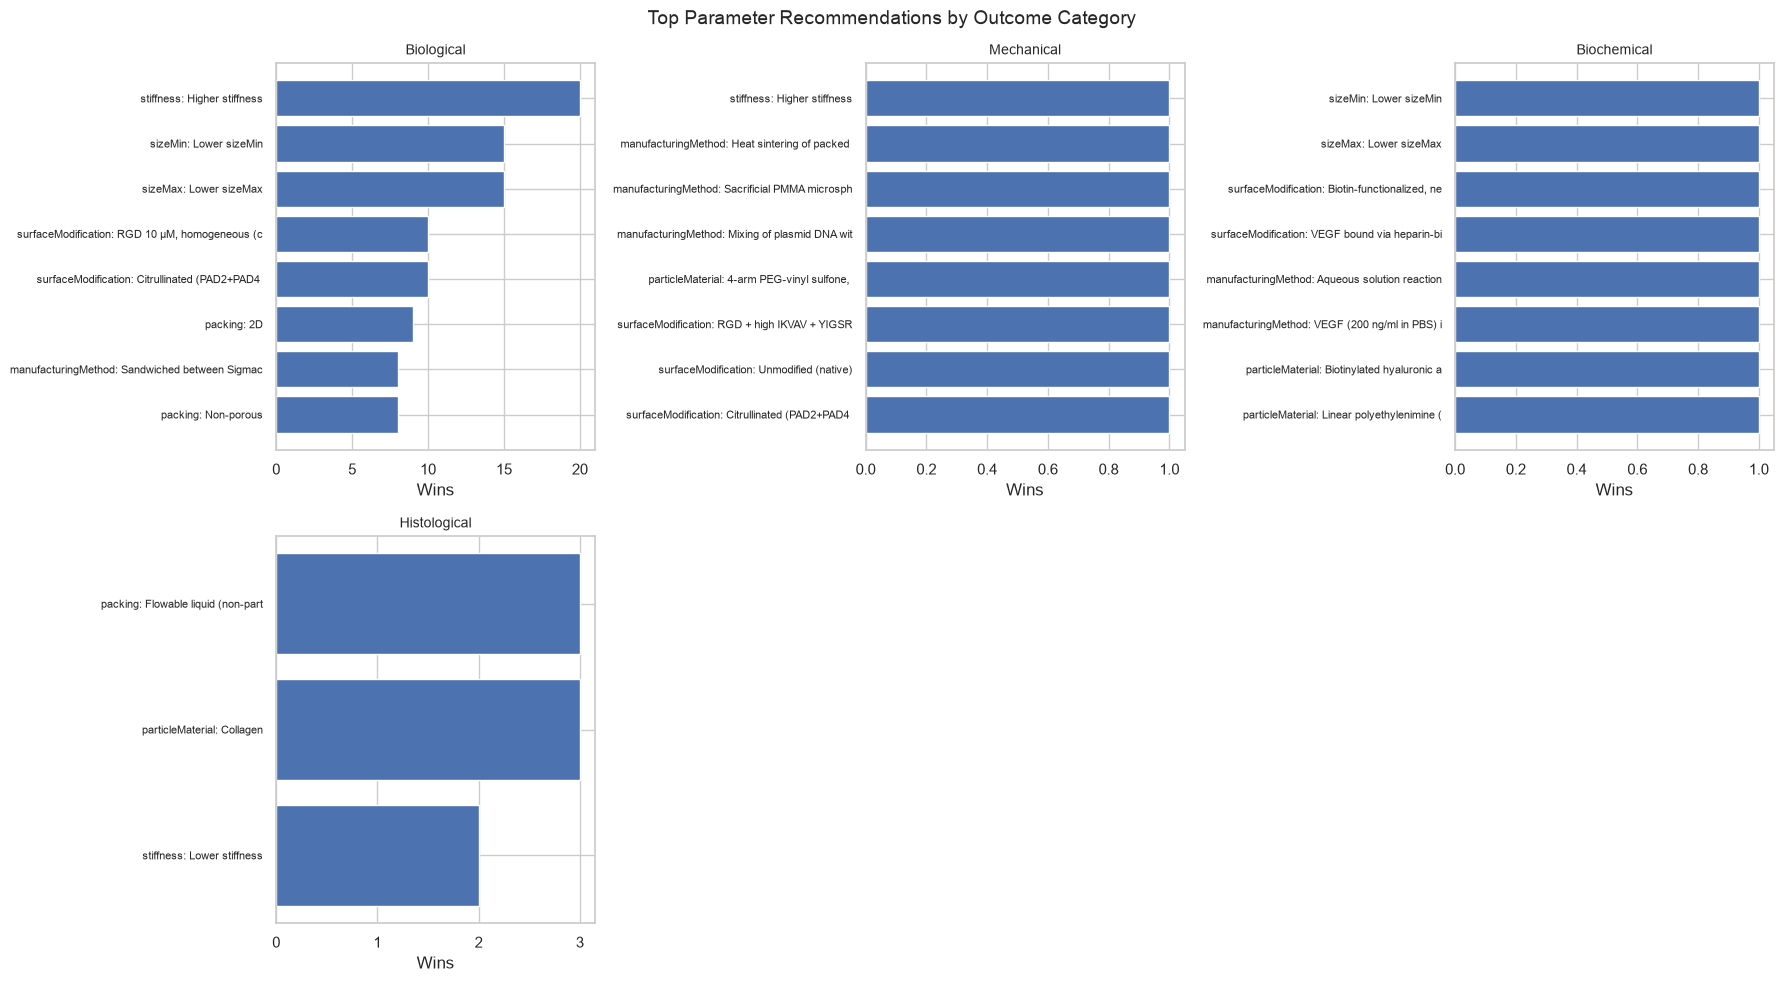

In [74]:
# ── Visualization: top parameter recommendations per outcome ──
top_cats = list(outcome_rankings.keys())[:6]  # top 6 outcome categories

if top_cats:
    n_cats = len(top_cats)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    
    for i, cat in enumerate(top_cats):
        ax = axes[i]
        rank_df = outcome_rankings[cat].head(8)
        labels = [f"{r['parameter']}: {r['recommendation'][:25]}" for _, r in rank_df.iterrows()]
        ax.barh(range(len(labels)), rank_df['wins'].values)
        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(labels, fontsize=8)
        ax.set_title(cat, fontsize=10)
        ax.set_xlabel('Wins')
        ax.invert_yaxis()
    
    # Hide unused axes
    for i in range(n_cats, len(axes)):
        axes[i].set_visible(False)
    
    fig.suptitle('Top Parameter Recommendations by Outcome Category', fontsize=14)
    plt.tight_layout()
    plt.show()

## 6. Tradeoff Detection

Find parameters where winning for one outcome category means losing for another.
E.g., "Lower crosslinker ratio improves biology but hurts mechanics."

These are the most interesting for hypothesis generation — they define the
design space boundaries.

In [75]:
# ── Tradeoff detection ──
# For each (parameter, valueA, valueB) pair, check if valueA wins for some
# outcome categories but loses (i.e. valueB wins) for others.

# Build a lookup: for each ordered pair (param, val1, val2), which outcome cats does val1 win?
pair_wins = defaultdict(lambda: defaultdict(int))  # (param, valA, valB) -> {outcome_cat: count}
pair_papers = defaultdict(lambda: defaultdict(set))  # (param, valA, valB) -> {outcome_cat: {dois}}

for _, row in sig_diffs.iterrows():
    if row['measCatA'] == '':
        continue
    key = (row['param'], row['valueA'], row['valueB'])
    pair_wins[key][row['measCatA']] += 1
    pair_papers[key][row['measCatA']].add(row['doi'])

# Find tradeoffs: same (param, {val1, val2}) pair where val1 wins for cat X and val2 wins for cat Y
tradeoff_rows = []
seen_pairs = set()

for (param, valA, valB), wins_by_cat in pair_wins.items():
    reverse_key = (param, valB, valA)
    if reverse_key not in pair_wins:
        continue
    
    # Canonicalize to avoid duplicates
    canon = tuple(sorted([valA, valB]))
    pair_id = (param, canon[0], canon[1])
    if pair_id in seen_pairs:
        continue
    seen_pairs.add(pair_id)
    
    forward_cats = set(wins_by_cat.keys())
    reverse_cats = set(pair_wins[reverse_key].keys())
    
    # Categories where each value wins
    a_only = forward_cats - reverse_cats  # valA wins exclusively
    b_only = reverse_cats - forward_cats  # valB wins exclusively
    
    if a_only and b_only:
        # This is a genuine tradeoff
        total_a = sum(wins_by_cat[c] for c in a_only)
        total_b = sum(pair_wins[reverse_key][c] for c in b_only)
        papers_a = len(set().union(*(pair_papers[(param, valA, valB)][c] for c in a_only)))
        papers_b = len(set().union(*(pair_papers[reverse_key][c] for c in b_only)))
        
        tradeoff_rows.append({
            'parameter': param,
            'value_1': valA,
            'value_2': valB,
            'value_1_wins_for': ', '.join(sorted(a_only)),
            'value_2_wins_for': ', '.join(sorted(b_only)),
            'contested_cats': ', '.join(sorted(forward_cats & reverse_cats)),
            'v1_exclusive_wins': total_a,
            'v2_exclusive_wins': total_b,
            'total_evidence': total_a + total_b,
            'papers': papers_a + papers_b,
        })

tradeoff_df = pd.DataFrame(tradeoff_rows)
if not tradeoff_df.empty:
    tradeoff_df = tradeoff_df.sort_values('total_evidence', ascending=False)
    print(f"=== Tradeoffs Detected: {len(tradeoff_df)} ===")
    print("These are parameter value pairs that improve one outcome but worsen another.\n")
    display(tradeoff_df.head(20))
else:
    print("No tradeoffs detected between outcome categories")

=== Tradeoffs Detected: 4 ===
These are parameter value pairs that improve one outcome but worsen another.



,parameter,value_1,value_2,value_1_wins_for,value_2_wins_for,contested_cats,v1_exclusive_wins,v2_exclusive_wins,total_evidence,papers
2,packing,Jammed,Non-porous,"Biological, Rheological",Diffusion,,2,1,3,3
0,sizeMin,125.0,35.0,Biological,Biochemical,,1,1,2,2
1,sizeMax,135.0,45.0,Biological,Biochemical,,1,1,2,2
3,manufacturingMethod,"Bulk mixing of PEG-VS, MMPxl crosslinker, and RGD peptide; gelation between ...","Mixing of plasmid DNA with linear PEI in DI water, vortex and incubation",Biological,Mechanical,,1,1,2,2


In [76]:
# ── Natural-language tradeoff descriptions ──
nl_tradeoffs = []

if not tradeoff_df.empty:
    for _, t in tradeoff_df.iterrows():
        text = (
            f"TRADEOFF in {t['parameter']}: "
            f"'{t['value_1'][:40]}' is better for {t['value_1_wins_for']} "
            f"({t['v1_exclusive_wins']} wins), but "
            f"'{t['value_2'][:40]}' is better for {t['value_2_wins_for']} "
            f"({t['v2_exclusive_wins']} wins). "
            f"Evidence from {t['papers']} paper(s)."
        )
        nl_tradeoffs.append(text)
    
    print("=== Tradeoff Descriptions ===\n")
    for i, t in enumerate(nl_tradeoffs[:10]):
        print(f"{i+1}. {t}\n")
else:
    print("No tradeoffs to describe")

=== Tradeoff Descriptions ===

1. TRADEOFF in packing: 'Jammed' is better for Biological, Rheological (2 wins), but 'Non-porous' is better for Diffusion (1 wins). Evidence from 3 paper(s).

2. TRADEOFF in sizeMin: '125.0' is better for Biological (1 wins), but '35.0' is better for Biochemical (1 wins). Evidence from 2 paper(s).

3. TRADEOFF in sizeMax: '135.0' is better for Biological (1 wins), but '45.0' is better for Biochemical (1 wins). Evidence from 2 paper(s).

4. TRADEOFF in manufacturingMethod: 'Bulk mixing of PEG-VS, MMPxl crosslinker' is better for Biological (1 wins), but 'Mixing of plasmid DNA with linear PEI in' is better for Mechanical (1 wins). Evidence from 2 paper(s).



In [77]:
# ── For quantitative params, check directional tradeoffs ──
# E.g., higher stiffness → better mechanical but worse biological
quant_params = ['stiffness', 'sizeMin', 'sizeMax']
quant_diffs = sig_diffs[sig_diffs['param'].isin(quant_params) & sig_diffs['winner_has_higher'].notna()].copy()

quant_tradeoff_rows = []
for param in quant_params:
    param_data = quant_diffs[quant_diffs['param'] == param]
    if len(param_data) < 3:
        continue
    
    for cat in param_data['measCatA'].unique():
        if cat == '':
            continue
        cat_data = param_data[param_data['measCatA'] == cat]
        if len(cat_data) < 2:
            continue
        higher_wins = cat_data['winner_has_higher'].mean()
        quant_tradeoff_rows.append({
            'parameter': param,
            'outcome_category': cat,
            'higher_win_rate': higher_wins,
            'direction': 'higher better' if higher_wins > 0.6 else ('lower better' if higher_wins < 0.4 else 'mixed'),
            'n_comparisons': len(cat_data),
            'papers': cat_data['doi'].nunique(),
        })

quant_tradeoff_df = pd.DataFrame(quant_tradeoff_rows)
if not quant_tradeoff_df.empty:
    quant_tradeoff_df = quant_tradeoff_df.sort_values('n_comparisons', ascending=False)
    print("=== Quantitative Parameter Direction by Outcome ===")
    print("Does higher or lower value win for each outcome?\n")
    display(quant_tradeoff_df)
else:
    print("Not enough quantitative data for directional analysis")

=== Quantitative Parameter Direction by Outcome ===
Does higher or lower value win for each outcome?



,parameter,outcome_category,higher_win_rate,direction,n_comparisons,papers
0,stiffness,Biological,0.600000,mixed,20,6
2,sizeMin,Biological,0.266667,lower better,15,7
4,sizeMax,Biological,0.266667,lower better,15,7
1,stiffness,Histological,0.500000,mixed,2,1
3,sizeMin,Physicochemical,1.000000,higher better,2,1
5,sizeMax,Physicochemical,1.000000,higher better,2,1


## 7. Untested Combinations (Gap Hypotheses)

Build material "fingerprints" and find parameter value combinations
that have never been tested together.

In [78]:
# ── Build material fingerprints from SPARQL ──
mat_props = query("""
SELECT ?mat ?matLabel ?particleMaterial ?particleShape ?packing
       ?surfaceMod ?stiffness ?sizeMin ?sizeMax
       ?annealingChem ?mfgMethod
WHERE {
  ?mat a lova:Material ;
       rdfs:label ?matLabel .
  OPTIONAL { ?mat lova:particleMaterial ?particleMaterial }
  OPTIONAL { ?mat lova:particleShape ?particleShape }
  OPTIONAL { ?mat lova:packingConfiguration ?packing }
  OPTIONAL { ?mat lova:surfaceModification ?surfaceMod }
  OPTIONAL { ?mat lova:stiffnessValue ?stiffness }
  OPTIONAL { ?mat lova:particleSizeMin ?sizeMin }
  OPTIONAL { ?mat lova:particleSizeMax ?sizeMax }
  OPTIONAL {
    ?mat lova:hasFabricationMethod ?fab .
    OPTIONAL { ?fab lova:annealingChemistry ?annealingChem }
    OPTIONAL { ?fab lova:manufacturingMethod ?mfgMethod }
  }
}
""")

# Deduplicate — keep row with most properties filled
fp_cols = ['particleMaterial', 'particleShape', 'packing', 'surfaceMod',
           'stiffness', 'sizeMin', 'sizeMax', 'annealingChem', 'mfgMethod']
mat_props['_fill'] = mat_props[fp_cols].apply(lambda r: sum(v != '' for v in r), axis=1)
mat_props = mat_props.sort_values('_fill', ascending=False).drop_duplicates('mat').drop(columns='_fill')

print(f"Materials with property data: {len(mat_props)}")
print(f"\nProperty fill rates:")
for col in fp_cols:
    filled = (mat_props[col] != '').sum()
    print(f"  {col}: {filled}/{len(mat_props)} ({filled/len(mat_props):.0%})")

Materials with property data: 652

Property fill rates:
  particleMaterial: 562/652 (86%)
  particleShape: 224/652 (34%)
  packing: 152/652 (23%)
  surfaceMod: 189/652 (29%)
  stiffness: 81/652 (12%)
  sizeMin: 136/652 (21%)
  sizeMax: 147/652 (23%)
  annealingChem: 205/652 (31%)
  mfgMethod: 505/652 (77%)


In [79]:
# ── Find tested pairwise parameter combinations ──
# For each base material, find which parameter value pairs have been tested
categorical_params = ['particleShape', 'packing', 'surfaceMod', 'annealingChem']

tested_combos = set()
for _, m in mat_props.iterrows():
    vals = {p: m[p] for p in categorical_params if m[p] != ''}
    params = list(vals.keys())
    for i in range(len(params)):
        for j in range(i + 1, len(params)):
            tested_combos.add((params[i], vals[params[i]], params[j], vals[params[j]]))

print(f"Tested parameter-value pair combinations: {len(tested_combos)}")

# ── Find winning values from design rules ──
winning_values = defaultdict(set)  # param -> {winning values}
for _, row in sig_diffs.iterrows():
    if row['param'] in categorical_params and row['valueA'] != '':
        winning_values[row['param']].add(row['valueA'])

print(f"\nWinning values per parameter:")
for param, vals in sorted(winning_values.items()):
    print(f"  {param}: {len(vals)} distinct winning values")

Tested parameter-value pair combinations: 134

Winning values per parameter:
  packing: 7 distinct winning values
  particleShape: 2 distinct winning values


In [80]:
# ── Untested combinations of individually-proven winning values ──
gap_rows = []

params_with_winners = [p for p in categorical_params if p in winning_values and len(winning_values[p]) >= 2]

for i in range(len(params_with_winners)):
    for j in range(i + 1, len(params_with_winners)):
        p1, p2 = params_with_winners[i], params_with_winners[j]
        # Top 5 winning values per param (by frequency in sig_diffs)
        top_v1 = sig_diffs[sig_diffs['param'] == p1]['valueA'].value_counts().head(5).index
        top_v2 = sig_diffs[sig_diffs['param'] == p2]['valueA'].value_counts().head(5).index
        
        for v1 in top_v1:
            for v2 in top_v2:
                if (p1, v1, p2, v2) not in tested_combos and (p2, v2, p1, v1) not in tested_combos:
                    gap_rows.append({
                        'param_1': p1,
                        'value_1': v1[:50],
                        'param_2': p2,
                        'value_2': v2[:50],
                    })

gap_df = pd.DataFrame(gap_rows)
print(f"=== Untested Combinations of Winning Values: {len(gap_df)} ===")
if not gap_df.empty:
    display(gap_df.head(30))
else:
    print("All top winning value combinations have been tested!")

=== Untested Combinations of Winning Values: 7 ===


,param_1,value_1,param_2,value_2
0,particleShape,Irregular,packing,2D
1,particleShape,Irregular,packing,Non-porous
2,particleShape,Irregular,packing,Flowable liquid (non-particulate)
3,particleShape,Ellipsoid,packing,2D
4,particleShape,Ellipsoid,packing,Non-porous
5,particleShape,Ellipsoid,packing,Jammed
6,particleShape,Ellipsoid,packing,Flowable liquid (non-particulate)


## 8. Hypothesis Generation & Scoring

Combine design rules, tradeoffs, and gaps into scored hypotheses.

Three hypothesis types:
- **A) Optimization**: combine best parameter values for different outcomes
- **B) Tradeoff resolution**: propose novel ways to break a known tradeoff
- **C) Untested combination**: propose combining individually-proven parameter values

Score = `log(wins+1) * log(papers+1) * consistency_rate * novelty_bonus`

In [81]:
# ── Type A: Optimization hypotheses from cross-paper design rules ──
hyp_a_rows = []

for _, rule in cross_paper_rules.iterrows():
    param = rule['parameter']
    outcome = rule['outcome_category']
    wins = rule['total_wins']
    papers = rule['papers']
    consistency = rule.get('consistency', 0.5)
    
    score = np.log1p(wins) * np.log1p(papers) * consistency
    
    if rule.get('quant_direction', ''):
        direction = rule['quant_direction']
        text = (f"OPTIMIZATION: Use {direction} {param} to improve {outcome}. "
                f"Evidence: {wins} wins across {papers} papers "
                f"(consistency: {consistency:.0%}). "
                f"Base materials: {rule['base_materials']}")
    else:
          winner = str(rule.get('top_winner', ''))
          if winner in ('', 'nan'):
              continue
          text = (f"OPTIMIZATION: Use {param}='{winner[:50]}' to improve {outcome}. "
                  f"Evidence: {wins} wins across {papers} papers "
                  f"(consistency: {consistency:.0%}). "
                  f"Base materials: {rule['base_materials']}")
    
    hyp_a_rows.append({
        'type': 'A_optimization',
        'hypothesis': text,
        'parameter': param,
        'outcome': outcome,
        'wins': wins,
        'papers': papers,
        'consistency': consistency,
        'score': score,
    })

print(f"Type A (Optimization) hypotheses: {len(hyp_a_rows)}")

Type A (Optimization) hypotheses: 14


In [82]:
# ── Type B: Tradeoff resolution hypotheses ──
hyp_b_rows = []

if not tradeoff_df.empty:
    for _, t in tradeoff_df.iterrows():
        total = t['total_evidence']
        papers = t['papers']
        score = np.log1p(total) * np.log1p(papers) * 1.5  # novelty bonus for tradeoffs
        
        text = (
            f"TRADEOFF RESOLUTION: {t['parameter']} shows a tradeoff — "
            f"'{t['value_1'][:35]}' benefits {t['value_1_wins_for']}, "
            f"while '{t['value_2'][:35]}' benefits {t['value_2_wins_for']}. "
            f"Hypothesis: engineer an intermediate or hybrid {t['parameter']} "
            f"to capture benefits of both. Evidence: {total} total wins from {papers} paper(s)."
        )
        
        hyp_b_rows.append({
            'type': 'B_tradeoff',
            'hypothesis': text,
            'parameter': t['parameter'],
            'outcome': f"{t['value_1_wins_for']} vs {t['value_2_wins_for']}",
            'wins': total,
            'papers': papers,
            'consistency': 0.5,  # inherently contested
            'score': score,
        })

print(f"Type B (Tradeoff Resolution) hypotheses: {len(hyp_b_rows)}")

Type B (Tradeoff Resolution) hypotheses: 4


In [83]:
# ── Type C: Untested combination hypotheses ──
hyp_c_rows = []

if not gap_df.empty:
    # Score each gap by how often each individual value wins
    val_win_counts = sig_diffs.groupby(['param', 'valueA']).size().to_dict()
    val_paper_counts = sig_diffs.groupby(['param', 'valueA'])['doi'].nunique().to_dict()
    
    for _, gap in gap_df.iterrows():
        wins_1 = val_win_counts.get((gap['param_1'], gap['value_1']), 0)
        wins_2 = val_win_counts.get((gap['param_2'], gap['value_2']), 0)
        papers_1 = val_paper_counts.get((gap['param_1'], gap['value_1']), 0)
        papers_2 = val_paper_counts.get((gap['param_2'], gap['value_2']), 0)
        
        combined_wins = wins_1 + wins_2
        combined_papers = papers_1 + papers_2
        novelty_bonus = 2.0  # high novelty for untested combos
        
        score = np.log1p(combined_wins) * np.log1p(combined_papers) * novelty_bonus
        
        text = (
            f"UNTESTED COMBINATION: Combine {gap['param_1']}='{gap['value_1']}' "
            f"(proven: {wins_1} wins in {papers_1} papers) with "
            f"{gap['param_2']}='{gap['value_2']}' "
            f"(proven: {wins_2} wins in {papers_2} papers). "
            f"This combination has never been tested."
        )
        
        hyp_c_rows.append({
            'type': 'C_untested_combo',
            'hypothesis': text,
            'parameter': f"{gap['param_1']} + {gap['param_2']}",
            'outcome': 'multiple',
            'wins': combined_wins,
            'papers': combined_papers,
            'consistency': 0.5,
            'score': score,
        })

print(f"Type C (Untested Combination) hypotheses: {len(hyp_c_rows)}")

Type C (Untested Combination) hypotheses: 7


In [84]:
# ── Combine and rank all hypotheses ──
all_hypotheses = pd.DataFrame(hyp_a_rows + hyp_b_rows + hyp_c_rows)

if not all_hypotheses.empty:
    all_hypotheses = all_hypotheses.sort_values('score', ascending=False).reset_index(drop=True)
    all_hypotheses.index.name = 'rank'
    all_hypotheses.index += 1
    
    print(f"=== ALL HYPOTHESES: {len(all_hypotheses)} total ===")
    print(f"  Type A (Optimization): {len(hyp_a_rows)}")
    print(f"  Type B (Tradeoff): {len(hyp_b_rows)}")
    print(f"  Type C (Untested): {len(hyp_c_rows)}")
    print()
    
    summary = all_hypotheses[['type', 'parameter', 'outcome', 'wins', 'papers', 'score']].copy()
    summary['score'] = summary['score'].map('{:.2f}'.format)
    display(summary.head(30))
else:
    print("No hypotheses generated")

=== ALL HYPOTHESES: 25 total ===
  Type A (Optimization): 14
  Type B (Tradeoff): 4
  Type C (Untested): 7



,type,parameter,outcome,wins,papers,score
rank,,,,,,
1,C_untested_combo,particleShape + packing,multiple,12,3,7.11
2,C_untested_combo,particleShape + packing,multiple,10,3,6.65
3,C_untested_combo,particleShape + packing,multiple,12,2,5.64
4,C_untested_combo,particleShape + packing,multiple,10,2,5.27
5,C_untested_combo,particleShape + packing,multiple,4,4,5.18
6,C_untested_combo,particleShape + packing,multiple,6,2,4.28
7,A_optimization,sizeMax,Biological,15,7,4.23
8,A_optimization,sizeMin,Biological,15,7,4.23
9,A_optimization,stiffness,Biological,20,6,3.55


In [85]:
# ── Print top hypotheses as natural language ──
if not all_hypotheses.empty:
    print("=" * 80)
    print("TOP 20 HYPOTHESES (ranked by evidence score)")
    print("=" * 80)
    
    for i, (_, hyp) in enumerate(all_hypotheses.head(20).iterrows()):
        print(f"\n#{i+1} [Score: {hyp['score']:.2f}] [{hyp['type']}]")
        print(textwrap.fill(hyp['hypothesis'], width=90, initial_indent='  ', subsequent_indent='  '))
        print()

TOP 20 HYPOTHESES (ranked by evidence score)

#1 [Score: 7.11] [C_untested_combo]
  UNTESTED COMBINATION: Combine particleShape='Irregular' (proven: 3 wins in 1 papers)
  with packing='Non-porous' (proven: 9 wins in 2 papers). This combination has never been
  tested.


#2 [Score: 6.65] [C_untested_combo]
  UNTESTED COMBINATION: Combine particleShape='Ellipsoid' (proven: 1 wins in 1 papers)
  with packing='Non-porous' (proven: 9 wins in 2 papers). This combination has never been
  tested.


#3 [Score: 5.64] [C_untested_combo]
  UNTESTED COMBINATION: Combine particleShape='Irregular' (proven: 3 wins in 1 papers)
  with packing='2D' (proven: 9 wins in 1 papers). This combination has never been tested.


#4 [Score: 5.27] [C_untested_combo]
  UNTESTED COMBINATION: Combine particleShape='Ellipsoid' (proven: 1 wins in 1 papers)
  with packing='2D' (proven: 9 wins in 1 papers). This combination has never been tested.


#5 [Score: 5.18] [C_untested_combo]
  UNTESTED COMBINATION: Combine partic

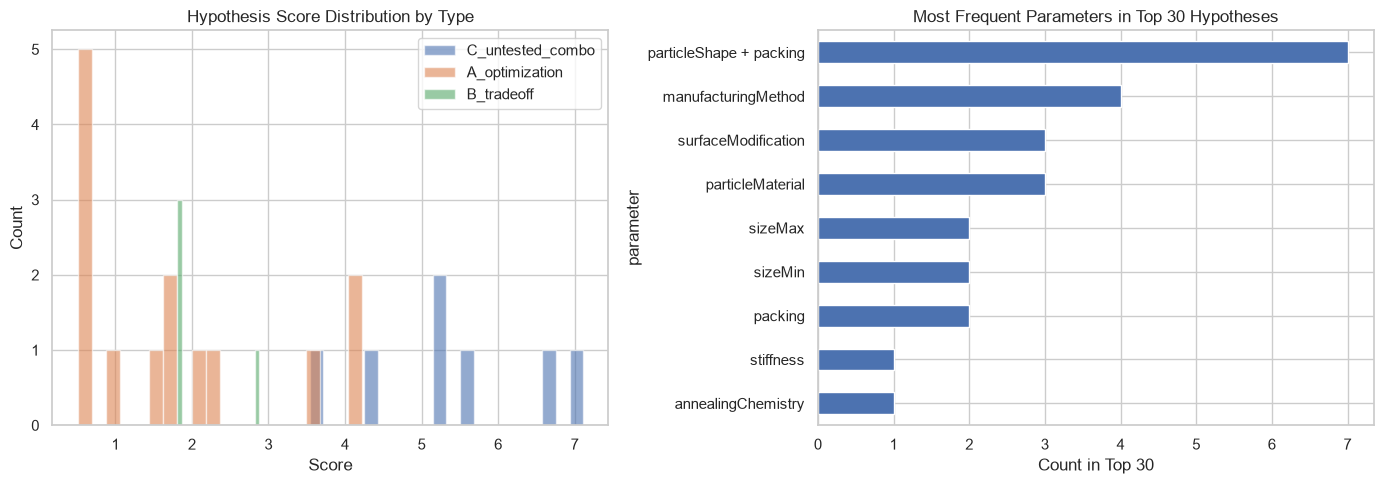

In [86]:
# ── Hypothesis score distribution ──
if not all_hypotheses.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Score distribution by type
    for htype in all_hypotheses['type'].unique():
        subset = all_hypotheses[all_hypotheses['type'] == htype]
        axes[0].hist(subset['score'], bins=20, alpha=0.6, label=htype)
    axes[0].set_xlabel('Score')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Hypothesis Score Distribution by Type')
    axes[0].legend()
    
    # Top hypotheses by parameter
    top30 = all_hypotheses.head(30)
    param_counts = top30['parameter'].value_counts().head(10)
    param_counts.plot.barh(ax=axes[1])
    axes[1].set_xlabel('Count in Top 30')
    axes[1].set_title('Most Frequent Parameters in Top 30 Hypotheses')
    axes[1].invert_yaxis()
    
    plt.tight_layout()
    plt.show()

## 9. Cross-Material Comparisons

Separately handle the true cross-material comparisons where materialA and materialB
are genuinely different base materials. These are rare but directly answer
"material A vs material B."

In [87]:
# ── Cross-material comparisons ──
cross_mat = cmp_df[cmp_df['cmp_type'] == 'cross_material'].copy()
print(f"Cross-material comparisons: {len(cross_mat)}")

if not cross_mat.empty:
    # Significant cross-material comparisons
    cross_sig = cross_mat[
        (cross_mat['significant'] == 'true') &
        (cross_mat['direction'].isin(['higher', 'lower']))
    ]
    print(f"Significant directional: {len(cross_sig)}")
    print(f"Papers: {cross_mat['doi'].nunique()}")
    
    # Material A vs Material B matchups
    matchups = cross_sig.groupby(['particleMaterialA', 'particleMaterialB']).agg(
        wins=('cmp', 'nunique'),
        papers=('doi', 'nunique'),
        outcomes=('measCatA', 'nunique'),
    ).reset_index()
    matchups = matchups.sort_values('wins', ascending=False)
    
    print(f"\nCross-material matchups (significant):")
    display(matchups.head(20))

Cross-material comparisons: 199
Significant directional: 106
Papers: 46

Cross-material matchups (significant):


,particleMaterialA,particleMaterialB,wins,papers,outcomes
0,,,18,7,3
1,,HA-NB,9,1,1
23,HA-AC,,6,2,1
5,"4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker","4-arm PEG-vinyl sulfone, L-chirality MMP crosslinker",4,1,1
25,HA-AC,iPS-derived neural progenitor cells (iPS-NPC),4,1,1
49,sPEG-PEI (PEGylated low-molecular-weight PEI),Linear PEI (25 kDa),4,1,1
9,4-arm star-PEG113-PPS5 block copolymer + vemurafenib,4-arm star-PEG113-PPS5 block copolymer,3,1,1
24,HA-AC,Fibrin,3,1,1
11,Collagen,PEG-VS,3,1,1
4,"4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker","4-arm PEG-vinyl sulfone, L- and D-chirality MMP crosslinkers (1:1 v/v)",3,1,2


In [88]:
# ── Cross-material outcome breakdown ──
if not cross_mat.empty:
    cross_sig_detail = cross_mat[
        (cross_mat['significant'] == 'true') &
        (cross_mat['direction'].isin(['higher', 'lower'])) &
        (cross_mat['measCatA'] != '')
    ].copy()
    
    if not cross_sig_detail.empty:
        cross_summary = cross_sig_detail.groupby(['particleMaterialA', 'particleMaterialB', 'measCatA']).agg(
            wins=('cmp', 'nunique'),
        ).reset_index()
        cross_summary.columns = ['winner_material', 'loser_material', 'outcome_category', 'wins']
        cross_summary = cross_summary.sort_values('wins', ascending=False)
        
        print("Cross-material results by outcome category:")
        display(cross_summary.head(30))
    else:
        print("No detailed cross-material data available")
else:
    print("No cross-material comparisons found")

Cross-material results by outcome category:


,winner_material,loser_material,outcome_category,wins
1,,,Biological,16
2,,HA-NB,Biological,9
25,HA-AC,,Biological,6
51,sPEG-PEI (PEGylated low-molecular-weight PEI),Linear PEI (25 kDa),Biological,4
27,HA-AC,iPS-derived neural progenitor cells (iPS-NPC),Biological,4
7,"4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker","4-arm PEG-vinyl sulfone, L-chirality MMP crosslinker",Biological,4
11,4-arm star-PEG113-PPS5 block copolymer + vemurafenib,4-arm star-PEG113-PPS5 block copolymer,Biological,3
13,Collagen,PEG-VS,Histological,3
26,HA-AC,Fibrin,Biological,3
9,4-arm star-PEG113-PPS5 block copolymer,4-arm star-PEG113-PPS2.5 block copolymer,Biological,2


In [89]:
# ── Cross-material natural-language summaries ──
cross_mat_summaries = []

if not cross_mat.empty:
    cross_sig_2 = cross_mat[
        (cross_mat['significant'] == 'true') &
        (cross_mat['direction'].isin(['higher', 'lower']))
    ]
    
    for (matA, matB), group in cross_sig_2.groupby(['particleMaterialA', 'particleMaterialB']):
        if matA == '' or matB == '':
            continue
        wins = len(group)
        cats = group[group['measCatA'] != '']['measCatA'].unique()
        papers = group['doi'].unique()
        
        text = (
            f"{matA} outperforms {matB} in {', '.join(cats[:3]) if len(cats) > 0 else 'measured outcomes'} "
            f"({wins} significant wins, {len(papers)} paper(s))"
        )
        cross_mat_summaries.append({'summary': text, 'wins': wins, 'papers': len(papers)})

if cross_mat_summaries:
    print("=== Cross-Material Findings ===\n")
    for i, s in enumerate(sorted(cross_mat_summaries, key=lambda x: -x['wins'])[:15]):
        print(f"{i+1}. {s['summary']}")
else:
    print("No cross-material summaries available")

=== Cross-Material Findings ===

1. 4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker outperforms 4-arm PEG-vinyl sulfone, L-chirality MMP crosslinker in Biological (4 significant wins, 1 paper(s))
2. HA-AC outperforms iPS-derived neural progenitor cells (iPS-NPC) in Biological (4 significant wins, 1 paper(s))
3. sPEG-PEI (PEGylated low-molecular-weight PEI) outperforms Linear PEI (25 kDa) in Biological (4 significant wins, 1 paper(s))
4. 4-arm PEG-vinyl sulfone, D-chirality MMP crosslinker outperforms 4-arm PEG-vinyl sulfone, L- and D-chirality MMP crosslinkers (1:1 v/v) in Biological, Mechanical (3 significant wins, 1 paper(s))
5. 4-arm star-PEG113-PPS5 block copolymer + vemurafenib outperforms 4-arm star-PEG113-PPS5 block copolymer in Biological (3 significant wins, 1 paper(s))
6. Collagen outperforms PEG-VS in Histological (3 significant wins, 1 paper(s))
7. HA-AC outperforms Fibrin in Biological (3 significant wins, 1 paper(s))
8. 4-arm star-PEG113-PPS5 block copolymer outperfo

## 10. Export

In [91]:
%run -i export_hypothesis_results.py

Exported to /Users/dzen/Documents/LOVAMAP/Repos/LOVAMAP_GW/KnowledgeBaseBackend/Research/hypothesis_results.html
